# Decode the Bioreactor — 01 Data exploration
Goal: understand the structure and quality of the data before modelling, and decide how to split batches for learning vs. testing on unseen runs.

**Sections**
0. Quick overview: structure, number of complete batches
1. Per-batch inventory
2. Missing values and physical consistency
3. Trajectories of the measured states
4. Feeds and volume
5. Outliers and noise
6. Batch-to-batch variability and input–outcome relations
7. Do the hidden test batches look like training?
8. Train / validation / hold-out split

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from bioreactor.data import load, STATES, FEEDS

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
df, tmpl, train_ids, test_ids = load(ROOT / "data")

## 0. Quick overview

In [2]:
print("file: bioreaction_remaining.csv")
print(f"  shape: {df.shape[0]} rows x {df.shape[1]} columns")
print(f"  columns: {list(df.columns)}")
print(f"  time range: {df.elapsed_time.min():.2f} to {df.elapsed_time.max():.2f} days\n")

# each row is ONE event: either an offline sample or a single feed addition
row_type = np.select(
    [df.vcd.notna(), df.to_predict, df[FEEDS].notna().any(axis=1)],
    ["sample (measured)", "sample (to predict)", "feed event"], "other")
print("row types:"); print(pd.Series(row_type).value_counts().to_string(), "\n")

print(f"batches total:                 {df.batch_id.nunique()}")
print(f"  complete (measured to end):  {len(train_ids)}")
print(f"  to predict (only day 0):     {len(test_ids)}  {test_ids}\n")

print("file: bioreaction_template.csv")
print(f"  shape: {tmpl.shape}, columns: {list(tmpl.columns)}")
print(f"  = {tmpl.groupby('batch_id').size().iloc[0]} time points x {tmpl.batch_id.nunique()} test batches, values to fill: {STATES}")

file: bioreaction_remaining.csv
  shape: 2858 rows x 12 columns
  columns: ['batch_id', 'elapsed_time', 'vcd', 'tcd', 'substrate', 'byproduct', 'feed_substrate', 'feed_b', 'feed_c', 'feed_d', 'volume', 'to_predict']
  time range: 0.00 to 13.00 days

row types:
feed event             2004
sample (measured)       698
sample (to predict)     156 

batches total:                 61
  complete (measured to end):  49
  to predict (only day 0):     12  ['Batch5', 'Batch6', 'Batch12', 'Batch24', 'Batch32', 'Batch35', 'Batch40', 'Batch48', 'Batch54', 'Batch56', 'Batch57', 'Batch60']

file: bioreaction_template.csv
  shape: (156, 6), columns: ['batch_id', 'elapsed_time', 'vcd', 'tcd', 'substrate', 'byproduct']
  = 13 time points x 12 test batches, values to fill: ['vcd', 'tcd', 'substrate', 'byproduct']


In [3]:
df.head(12)

,batch_id,elapsed_time,vcd,tcd,substrate,byproduct,feed_substrate,feed_b,feed_c,feed_d,volume,to_predict
0,Batch1,0.000000,0.979690,0.985251,4.507188,0.241840,NaN,NaN,NaN,NaN,10.500750,False
1,Batch1,0.996528,1.909271,1.929805,3.830345,0.940785,NaN,NaN,NaN,NaN,10.494285,False
2,Batch1,1.014977,NaN,NaN,NaN,NaN,NaN,0.062214,NaN,NaN,NaN,False
3,Batch1,1.984722,4.574543,4.611517,2.827742,1.860896,NaN,NaN,NaN,NaN,10.537027,False
4,Batch1,2.044421,NaN,NaN,NaN,NaN,NaN,0.136099,NaN,NaN,NaN,False
5,Batch1,2.722998,NaN,NaN,NaN,NaN,NaN,NaN,0.000854,NaN,NaN,False
6,Batch1,2.967361,7.489739,7.545903,2.362482,1.941632,NaN,NaN,NaN,NaN,10.695897,False
7,Batch1,2.981134,NaN,NaN,NaN,NaN,NaN,0.271894,NaN,NaN,NaN,False
8,Batch1,3.501829,NaN,NaN,NaN,NaN,NaN,NaN,0.000863,NaN,NaN,False
9,Batch1,3.970833,14.300371,14.405872,2.263021,2.301048,NaN,NaN,NaN,NaN,10.946566,False


## 1. Per-batch inventory

In [4]:
samp = df[df.vcd.notna()]
inv = pd.DataFrame({
    "n_samples": samp.groupby("batch_id").size(),
    "n_to_predict": df[df.to_predict].groupby("batch_id").size(),
    "t_last": df.groupby("batch_id").elapsed_time.max().round(2),
    **{f"n_{c}": df.groupby("batch_id")[c].count() for c in FEEDS},
}).fillna(0).astype({"n_samples": int, "n_to_predict": int})
inv["role"] = np.where(inv.index.isin(test_ids), "test", "train")
inv["complete"] = inv.n_samples >= 14
inv = inv.loc[sorted(inv.index, key=lambda b: int(b[5:]))]
print(inv.groupby("role").complete.value_counts().to_string())
inv

role   complete
test   False       12
train  True        49


,n_samples,n_to_predict,t_last,n_feed_substrate,n_feed_b,n_feed_c,n_feed_d,role,complete
batch_id,,,,,,,,,
Batch1,14,0,13.00,2,12,16,3,train,True
Batch2,14,0,12.88,2,12,16,3,train,True
Batch3,14,0,12.91,2,12,23,3,train,True
Batch4,14,0,12.87,2,12,12,3,train,True
Batch5,1,13,12.88,2,12,12,3,test,False
...,...,...,...,...,...,...,...,...,...
Batch57,1,13,12.91,2,12,26,3,test,False
Batch58,14,0,12.99,2,12,13,3,train,True
Batch59,14,0,12.90,2,12,11,3,train,True


## 2. Missing values and physical consistency

In [5]:
tr = df[df.batch_id.isin(train_ids)]
s = tr[tr.vcd.notna()].copy()
s["day"] = s.elapsed_time.round().astype(int)
print("missing values in sample rows:\n", s[STATES + ["volume"]].isna().sum().to_string())
print("\nsamples per (batch, day):", s.groupby(["batch_id", "day"]).size().value_counts().to_dict())
print(f"sampling-time jitter vs whole day: median {((s.elapsed_time - s.day).abs().median()*24):.1f} h, "
      f"max {((s.elapsed_time - s.day).abs().max()*24):.1f} h")
print(f"rows with TCD < VCD: {(s.tcd < s.vcd).sum()}")
s["viability"] = s.vcd / s.tcd
print(f"viability range: {s.viability.min():.3f} - {s.viability.max():.3f}")
print("negative values:", (s[STATES] < 0).sum().to_dict())

missing values in sample rows:
 vcd          0
tcd          0
substrate    0
byproduct    0
volume       0

samples per (batch, day): {1: 686}
sampling-time jitter vs whole day: median 0.9 h, max 4.3 h
rows with TCD < VCD: 0
viability range: 0.843 - 0.999
negative values: {'vcd': 0, 'tcd': 0, 'substrate': 0, 'byproduct': 0}


**Volume balance** — are feeds given as added volume [L]? Compare volume change between samples with feeds added in between.

dV ~ feeds regression: {'feed_substrate': 0.789, 'feed_b': 0.948, 'feed_c': -3.087, 'feed_d': 0.7, 'intercept': 0.003}
dV - sum(feeds): median -43 mL per interval (sampling / evaporation)


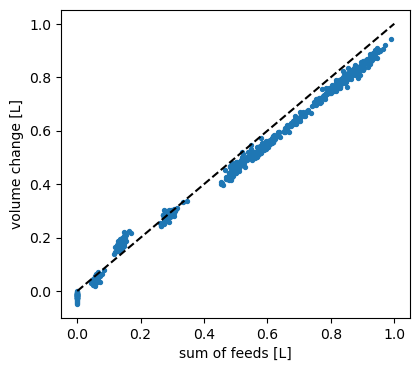

In [6]:
rows = []
for b, g in tr.groupby("batch_id"):
    v = g[g.volume.notna()]
    for (t0, v0), (t1, v1) in zip(v[["elapsed_time", "volume"]].values[:-1], v[["elapsed_time", "volume"]].values[1:]):
        m = (g.elapsed_time > t0) & (g.elapsed_time <= t1)
        rows.append([b, t1, v1 - v0, *g.loc[m, FEEDS].sum().values])
vb = pd.DataFrame(rows, columns=["batch_id", "t", "dV"] + FEEDS)
X = np.c_[vb[FEEDS].values, np.ones(len(vb))]
coef = np.linalg.lstsq(X, vb.dV, rcond=None)[0]
print("dV ~ feeds regression:", dict(zip(FEEDS + ["intercept"], coef.round(3))))
gap = vb.dV - vb[FEEDS].sum(axis=1)
print(f"dV - sum(feeds): median {gap.median()*1000:.0f} mL per interval (sampling / evaporation)")
plt.figure(figsize=(4.5, 4)); plt.scatter(vb[FEEDS].sum(axis=1), vb.dV, s=8)
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("sum of feeds [L]"); plt.ylabel("volume change [L]"); plt.show()

## 3. Trajectories of the measured states

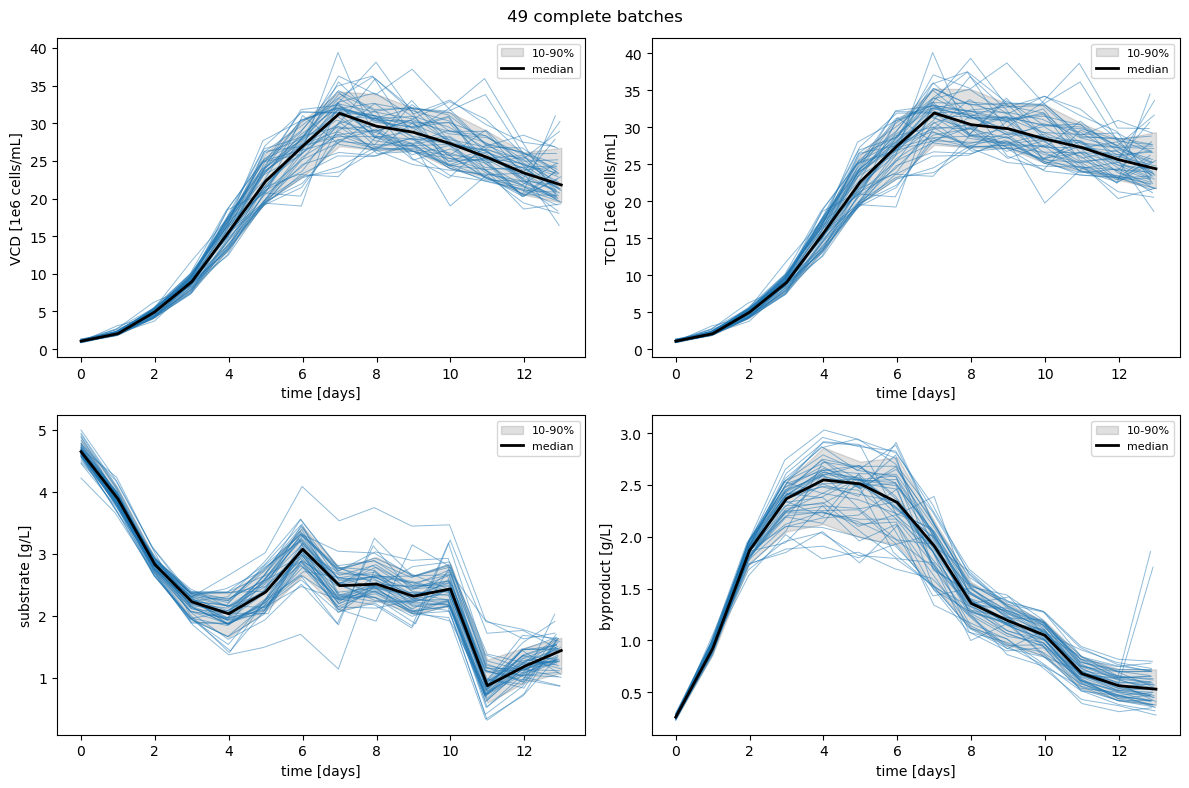

In [7]:
UNITS = {"vcd": "VCD [1e6 cells/mL]", "tcd": "TCD [1e6 cells/mL]", "substrate": "substrate [g/L]", "byproduct": "byproduct [g/L]"}
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for a, v in zip(ax.ravel(), STATES):
    for b, g in s.groupby("batch_id"):
        a.plot(g.elapsed_time, g[v], lw=0.7, alpha=0.5, color="tab:blue")
    q = s.groupby("day")[v].quantile([0.1, 0.5, 0.9]).unstack()
    a.fill_between(q.index, q[0.1], q[0.9], color="k", alpha=0.12, label="10-90%")
    a.plot(q.index, q[0.5], "k", lw=2, label="median")
    a.set_xlabel("time [days]"); a.set_ylabel(UNITS[v]); a.legend(fontsize=8)
fig.suptitle(f"{len(train_ids)} complete batches"); fig.tight_layout(); plt.show()

Interactive version — hover to identify batches (needs plotly).

In [8]:
try:
    import plotly.express as px
    long = s.melt(id_vars=["batch_id", "elapsed_time"], value_vars=STATES)
    fig = px.line(long, x="elapsed_time", y="value", color="batch_id", facet_col="variable",
                  facet_col_wrap=2, height=700)
    fig.update_yaxes(matches=None, showticklabels=True); fig.update_layout(showlegend=False); fig.show()
except ImportError:
    print("plotly not installed")

## 4. Feeds and volume

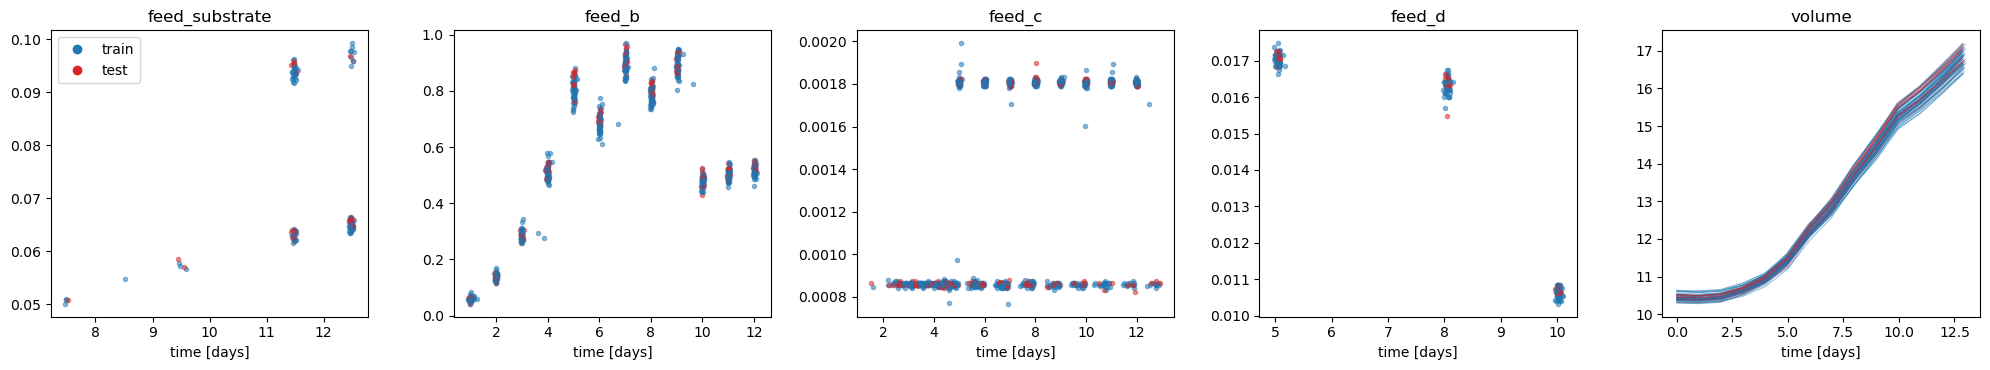

total feed volume per batch [L]:


,feed_substrate,feed_b,feed_c,feed_d
count,61.0000,61.0000,61.0000,61.0000
mean,0.1611,6.5758,0.0211,0.0440
std,0.0197,0.2083,0.0042,0.0004
min,0.1252,6.1805,0.0170,0.0430
25%,0.1579,6.4027,0.0180,0.0438
50%,0.1594,6.5770,0.0197,0.0439
75%,0.1624,6.7315,0.0222,0.0442
max,0.2098,6.9605,0.0375,0.0450


In [9]:
fig, ax = plt.subplots(1, 5, figsize=(20, 3.8))
for a, c in zip(ax, FEEDS + ["volume"]):
    for b, g in df.groupby("batch_id"):
        g = g[g[c].notna()]; col = "tab:red" if b in test_ids else "tab:blue"
        a.plot(g.elapsed_time, g[c], "-" if c == "volume" else "o", color=col, ms=3, lw=0.7, alpha=0.5)
    a.set_title(c); a.set_xlabel("time [days]")
ax[0].plot([], [], "o", c="tab:blue", label="train"); ax[0].plot([], [], "o", c="tab:red", label="test"); ax[0].legend()
fig.tight_layout(); plt.show()

ft = df.groupby("batch_id")[FEEDS].sum()
print("total feed volume per batch [L]:"); ft.describe().round(4)

## 5. Outliers and noise

In [10]:
flags = []
for v in STATES:
    grp = s.groupby("day")[v]
    med = grp.transform("median"); mad = grp.transform(lambda x: (x - x.median()).abs().median())
    z = (s[v] - med) / (1.4826 * mad + 1e-9)
    flags.append(s.loc[z.abs() > 4, ["batch_id", "elapsed_time", v]].assign(variable=v, z=z[z.abs() > 4].round(1)).rename(columns={v: "value"}))
flags = pd.concat(flags).sort_values("z", key=abs, ascending=False)
print(f"points with |robust z| > 4 vs. the across-batch median of that day: {len(flags)}")
flags

points with |robust z| > 4 vs. the across-batch median of that day: 13


,batch_id,elapsed_time,value,variable,z
1052,Batch29,12.852778,1.858505,byproduct,8.2
1327,Batch34,12.919444,1.707043,byproduct,7.2
1715,Batch42,7.936806,3.741318,substrate,5.5
237,Batch14,0.970833,3.100340,vcd,5.3
237,Batch14,0.970833,3.126549,tcd,5.0
518,Batch2,1.068056,1.109610,byproduct,4.8
1785,Batch44,0.000000,4.218942,substrate,-4.5
1719,Batch42,8.956250,3.443556,substrate,4.4
2237,Batch52,10.936111,1.930187,substrate,4.4
1726,Batch42,10.963889,1.901013,substrate,4.3


In [11]:
# within-batch spikes: point far off the (log-)mean of its neighbours
sp = []
for b, g in s.groupby("batch_id"):
    for v in STATES:
        ly = np.log(g[v].values)
        rel = np.exp(ly[1:-1] - (ly[:-2] + ly[2:]) / 2) - 1
        for i in np.where(np.abs(rel) > 0.25)[0]:
            sp.append((b, v, round(g.elapsed_time.values[i + 1], 2), round(rel[i], 2)))
sp = pd.DataFrame(sp, columns=["batch_id", "variable", "t", "rel_dev"])
print("spikes per variable:", sp.variable.value_counts().to_dict())
sp.sort_values("rel_dev", key=abs, ascending=False).head(15)

spikes per variable: {'substrate': 163, 'byproduct': 100, 'vcd': 11, 'tcd': 11}


,batch_id,variable,t,rel_dev
156,Batch36,substrate,9.97,1.59
15,Batch11,substrate,9.95,1.40
270,Batch7,substrate,9.91,1.28
135,Batch31,substrate,9.98,1.16
49,Batch17,substrate,9.94,1.09
130,Batch30,substrate,9.95,1.02
183,Batch41,substrate,9.95,1.00
251,Batch58,substrate,9.95,0.99
58,Batch19,substrate,9.96,0.93
83,Batch21,substrate,9.95,0.92


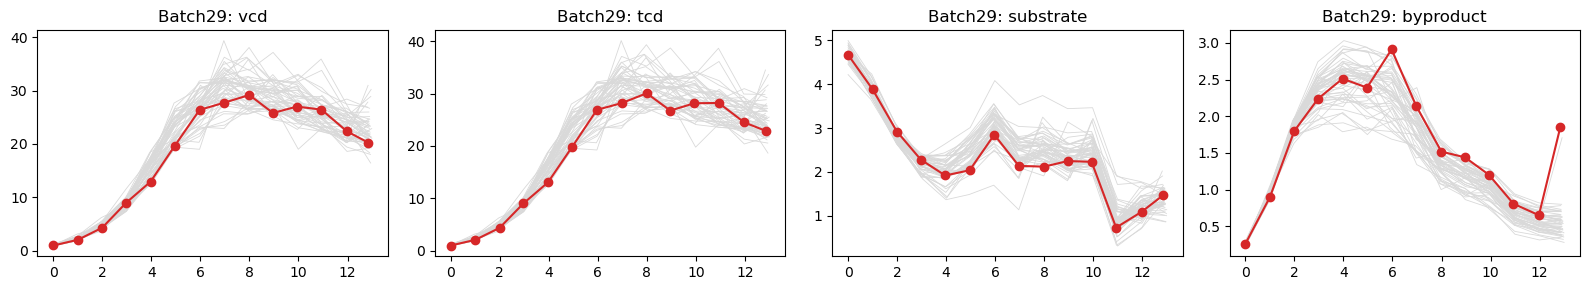

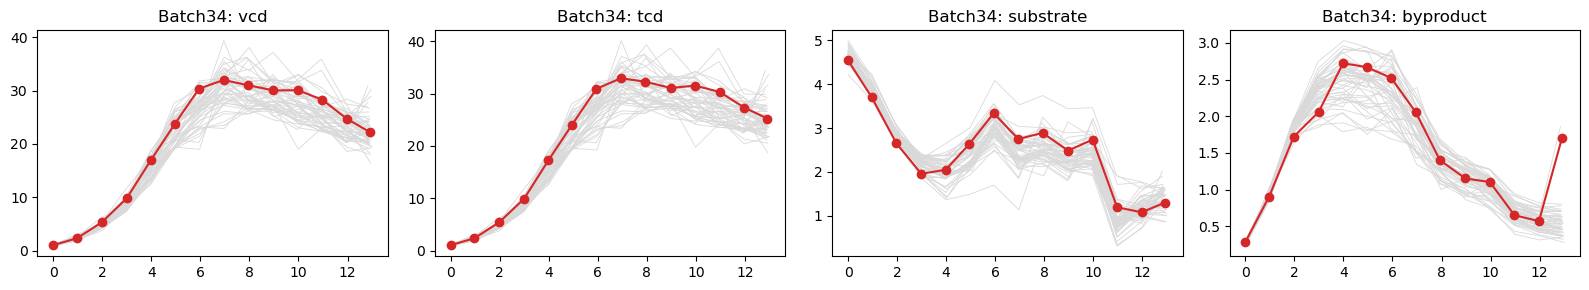

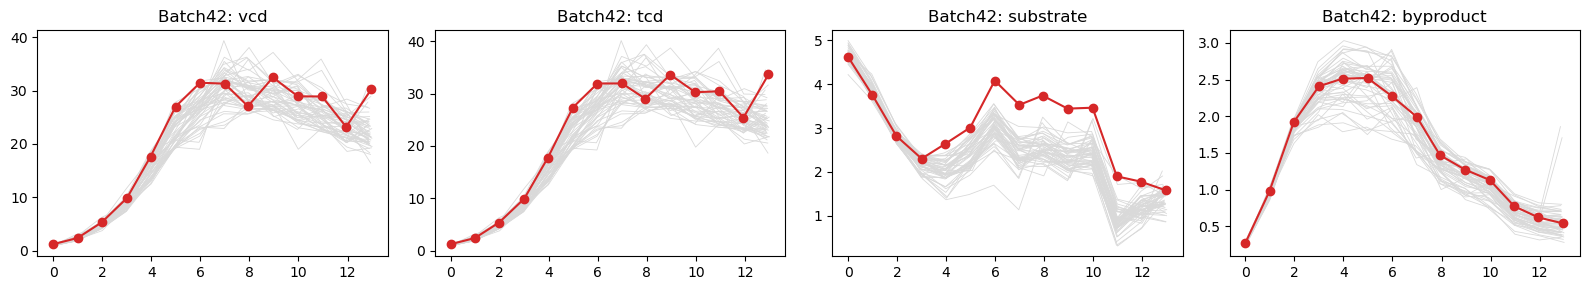

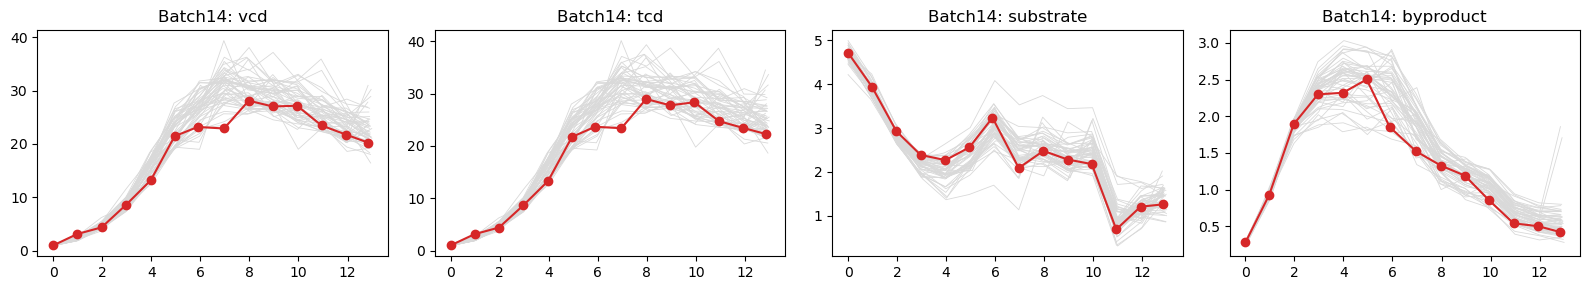

In [11]:
def show_batch(b):
    g = s[s.batch_id == b]
    fig, ax = plt.subplots(1, 4, figsize=(16, 3))
    for a, v in zip(ax, STATES):
        for _, h in s.groupby("batch_id"): a.plot(h.elapsed_time, h[v], c="0.85", lw=0.6)
        a.plot(g.elapsed_time, g[v], "o-", c="tab:red"); a.set_title(f"{b}: {v}")
    plt.tight_layout(); plt.show()

for b in ["Batch29", "Batch34", "Batch42", "Batch14"]:
    show_batch(b)

## 6. Batch-to-batch variability and input–outcome relations

CV% of inputs: {'d0_vcd': 10.7, 'd0_tcd': 11.0, 'd0_substrate': 2.8, 'd0_byproduct': 5.8, 'tot_feed_substrate': 12.6, 'tot_feed_b': 3.2, 'tot_feed_c': 20.5, 'tot_feed_d': 1.0}


,peak_vcd,final_vcd,peak_byp,min_S,t_peak
count,49.00,49.00,49.00,49.00,49.00
mean,31.74,22.47,2.55,0.86,7.74
std,2.97,3.08,0.26,0.26,1.15
min,26.39,16.42,1.93,0.31,5.95
25%,30.05,20.36,2.38,0.73,6.95
50%,31.77,21.80,2.59,0.86,7.89
75%,33.01,23.88,2.72,0.95,7.99
max,39.38,30.99,3.03,1.62,12.84


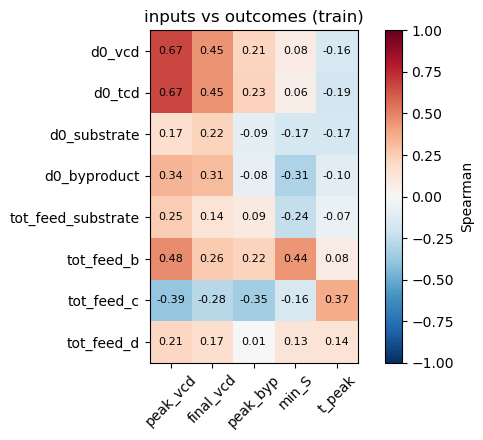

In [12]:
kpi = s.groupby("batch_id").agg(peak_vcd=("vcd", "max"), final_vcd=("vcd", "last"),
                               peak_byp=("byproduct", "max"), min_S=("substrate", "min"))
kpi["t_peak"] = s.loc[s.groupby("batch_id").vcd.idxmax()].set_index("batch_id").elapsed_time
ic = df[df.elapsed_time == 0].set_index("batch_id")[STATES]
inputs = pd.concat([ic.add_prefix("d0_"), ft.add_prefix("tot_")], axis=1)
print("CV% of inputs:", (100 * inputs.loc[train_ids].std() / inputs.loc[train_ids].mean()).round(1).to_dict())
display(kpi.describe().round(2))
corr = pd.concat([inputs.loc[train_ids], kpi], axis=1).corr("spearman").loc[inputs.columns, kpi.columns]
plt.figure(figsize=(6, 4.5)); plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45); plt.yticks(range(len(corr)), corr.index)
for i in range(corr.shape[0]):
    for j in range(corr.shape[1]): plt.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(label="Spearman"); plt.title("inputs vs outcomes (train)"); plt.tight_layout(); plt.show()

## 7. Do the hidden test batches look like training?

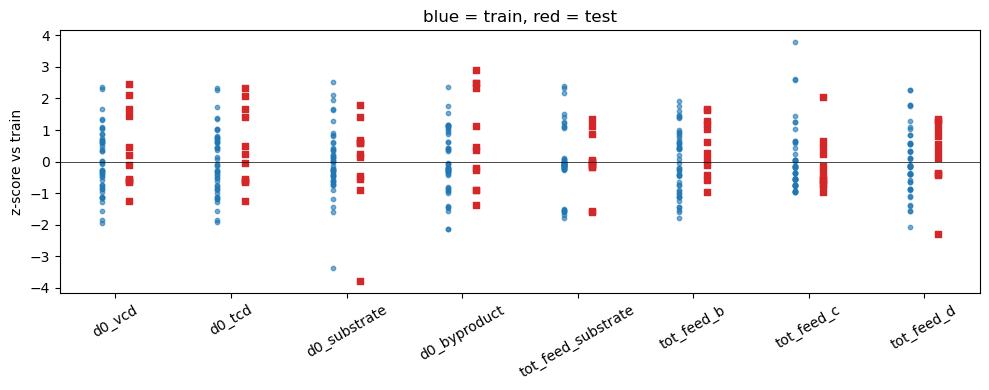

test batches with any |z| > 3: {'Batch54': {'d0_vcd': -0.1, 'd0_tcd': -0.05, 'd0_substrate': -3.78, 'd0_byproduct': 1.14, 'tot_feed_substrate': 1.36, 'tot_feed_b': 1.27, 'tot_feed_c': -0.34, 'tot_feed_d': 1.29}}


In [13]:
Z = (inputs - inputs.loc[train_ids].mean()) / inputs.loc[train_ids].std()
fig, ax = plt.subplots(figsize=(10, 4))
for i, c in enumerate(inputs.columns):
    ax.scatter(np.full(len(train_ids), i) - 0.12, Z.loc[train_ids, c], s=10, c="tab:blue", alpha=0.6)
    ax.scatter(np.full(len(test_ids), i) + 0.12, Z.loc[test_ids, c], s=14, c="tab:red", marker="s")
ax.set_xticks(range(len(inputs.columns))); ax.set_xticklabels(inputs.columns, rotation=30)
ax.axhline(0, c="k", lw=0.5); ax.set_ylabel("z-score vs train"); ax.set_title("blue = train, red = test")
plt.tight_layout(); plt.show()
print("test batches with any |z| > 3:", Z.loc[test_ids][(Z.loc[test_ids].abs() > 3).any(axis=1)].round(2).to_dict("index"))

## 8. Split: learning vs. testing on unseen batches
- Split by **whole batch**, never by rows (rows from one run are strongly correlated → leakage).
- 12 challenge test batches: only for the final submission.
- 10 measured batches as a **lock-box hold-out**: evaluated once at the end.
- 39 batches for **development** with 5-fold grouped cross-validation.
- Stratified on day-0 VCD (strongest predictor of the outcome). Generated by `src/make_splits.py`.

In [14]:
splits = pd.read_csv(ROOT / "outputs" / "splits.csv")
print(splits.role.value_counts().to_string())
print(splits[splits.role == "dev"].fold.value_counts().sort_index().to_dict())
sv = splits.merge(kpi.reset_index().rename(columns={"index": "batch_id"}), on="batch_id", how="left") \
           .merge(ic.vcd.rename("d0_vcd").reset_index(), on="batch_id")
sv.groupby("role")[["d0_vcd", "peak_vcd", "final_vcd", "peak_byp"]].agg(["mean", "std"]).round(2)

role
dev        39
test       12
holdout    10
{0: 8, 1: 7, 2: 8, 3: 8, 4: 8}


d0_vcd       peak_vcd       final_vcd       peak_byp      
          mean   std     mean   std      mean   std     mean   std
role                                                              
dev       1.08  0.12    31.77  2.93     22.39  3.05     2.54  0.28
holdout   1.07  0.12    31.63  3.27     22.79  3.36     2.57  0.19
test      1.12  0.14      NaN   NaN       NaN   NaN      NaN   NaN

## Take-aways
- 49 complete batches (14 daily samples each, no gaps); 12 to predict from day-0 + feed plan.
- Data are clean and physically consistent; a handful of suspicious points (Batch29/34 last-day byproduct, Batch42 substrate) — keep, but consider robust loss.
- Feeds are volumes [L]; feed B is the main daily feed, D fixed (days 5, 8, 10), substrate bolus late, C small and variable (likely on-demand).
- Day-0 VCD and feed totals explain part of the batch-to-batch spread → the model must use them.
- Test batches lie inside the training range (Batch54 slightly outside on one input).